[![Obre a Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# Nom i NIU

`Adrián Valverde Ambrosio` · `NIU: 1707952`

# Problema 2 · Regressió

> **Pregunta forta**
> Com sap una màquina si una recta és bona, i com la millora sense provar-les totes?

Treballareu amb `train.csv` (Ames, les mateixes cases de Problemes 1). Objectiu `y`: el preu (`SalePrice`, o `SalePrice/1000` si ho preferiu en milers).

## Com s'avalua (sobre 10)

| Exercici | Punts | Què es valora |
|---|---|---|
| Exercici 1 | 3 | Regressió lineal + Ridge + Lasso, α triat amb validation |
| Exercici 2 | 3 | Selecció de variables (mètode 1) mesurada contra 500 columnes de soroll |
| Exercici 3 | 3 | Selecció de variables (mètode 2, diferent) i decisió entre les dues |
| Exercici 4 | 1 | Defensa conceptual: avantatges, inconvenients i no-ús |

No n'hi ha prou amb el codi: cada exercici es tanca amb una Decisió (evidència · risc · límit).

**Regla d'or de sempre (§7.4)**, la de Problemes 1. Aquesta setmana també compten com a `fit` l'escalat, la selecció de variables i l'α que trieu: tot es calcula només amb train.

*Referències: llibre Tema 2 §2.1-2.6 (model, cost, gradient, regularització) i §7.4 (leakage).*

## Preparació de dades (comuna)

Completeu la càrrega i el *split*. Recordeu: imputeu i escaleu *després* de separar, ajustant només amb train.

In [1]:
# Importació de llibreries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.feature_selection import f_regression
from sklearn.metrics import r2_score

RANDOM_STATE = 42
NIU = 1707952

# Càrrega del dataset (train.csv al costat del notebook)
df = pd.read_csv('train.csv')

NUM_FEATURES = ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea',
                'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd',
                'YearBuilt', 'Fireplaces', 'LotArea', 'LotFrontage', 'MasVnrArea']

# Tria de variables i target (preu en milers)
y = df['SalePrice'] / 1000
X_real = df[NUM_FEATURES]

# Split train / validation / test = 60 / 20 / 20 (decisions amb validation, test intacte)
idx_tr, idx_tmp = train_test_split(df.index, test_size=0.4, random_state=RANDOM_STATE)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.5, random_state=RANDOM_STATE)
print(len(idx_tr), len(idx_va), len(idx_te))

876 292 292


## Exercici 1 (3 punts)

Treballeu amb les 13 variables numèriques del notebook (`NUM_FEATURES`) i afegiu-hi 500 columnes de soroll pur, generades amb `np.random.default_rng(NIU)`, on `NIU` és el vostre número (si entregueu en parella, el del primer). Aquesta matriu ampliada és la que fareu servir als Exercicis 1, 2 i 3.

Entreneu una regressió lineal sobre aquesta matriu i calculeu $R^2$ en train i en validation.

A continuació useu Ridge i Lasso. Per a cadascuna, determineu el valor òptim de $\alpha$ **mitjançant validation** (no amb test) i comenteu les diferències entre Ridge i Lasso i els resultats obtinguts. Només per al model que trieu com a final, calculeu $R^2$ en test, una sola vegada.

Per al Lasso, indiqueu quines variables queden amb coeficient exactament zero i quines sobreviuen amb l'$\alpha$ que heu triat. Aquesta llista és la que compareu als Exercicis 2 i 3.

### Prediu abans d'executar
Abans de calcular res: espereu que Ridge o Lasso deixin més coeficients a (prop de) zero? Per què?

### Predicció (abans d'executar)
Espero que el **Lasso** deixi més coeficients a zero. La penalització L1 ($\alpha\sum|\theta_j|$) té una "punta" a 0: per a variables poc útils (com el soroll) l'òptim és exactament 0. La Ridge (L2, $\alpha\sum\theta_j^2$) encongeix tots els coeficients cap a 0 però gairebé mai els fa exactament 0.

**Preparació:** `y = SalePrice/1000`. Split 60/20/20 (train/validation/test). La imputació (mediana) i l'escalat s'ajusten **només amb train**. Les 500 columnes de soroll es generen amb `np.random.default_rng(1707952)`.

Matriu ampliada: (1460, 513)


Lineal  R2 train = 0.889 | R2 val = 0.642


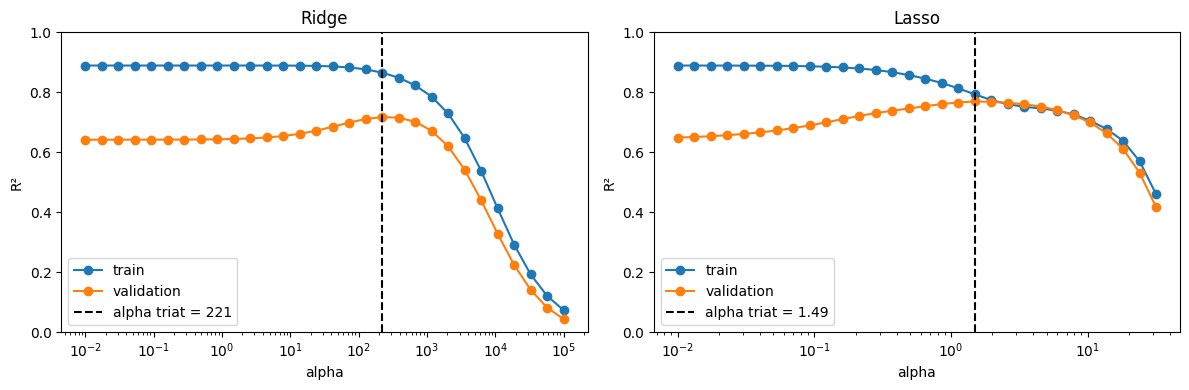

Ridge alpha=     221  R2 train = 0.866 | R2 val = 0.717 | coeficients = 0: 0 | |coef| < 0.1: 35
Lasso alpha=    1.49  R2 train = 0.793 | R2 val = 0.769 | coeficients = 0: 407 | |coef| < 0.1: 417

Lasso - reals que sobreviuen: ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'TotRmsAbvGrd', 'YearBuilt', 'Fireplaces', 'LotArea', 'MasVnrArea']
Lasso - reals a zero: ['FullBath', 'LotFrontage']
Lasso - columnes de soroll que sobreviuen: 95


In [2]:
# Matriu ampliada: NUM_FEATURES + 500 columnes de soroll (llavor NIU)
rng = np.random.default_rng(NIU)
soroll = pd.DataFrame(rng.normal(size=(len(df), 500)),
                      columns=[f'soroll_{i}' for i in range(500)], index=df.index)
X = pd.concat([X_real, soroll], axis=1)
COLS = X.columns
es_real = COLS.isin(NUM_FEATURES)

Xtr, Xva, Xte = X.loc[idx_tr], X.loc[idx_va], X.loc[idx_te]
ytr, yva, yte = y.loc[idx_tr], y.loc[idx_va], y.loc[idx_te]

# Imputació (mediana) i escalat ajustats NOMÉS amb train
prep = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()).fit(Xtr)
Ztr, Zva, Zte = prep.transform(Xtr), prep.transform(Xva), prep.transform(Xte)
print('Matriu ampliada:', X.shape)

# Regressió lineal + R2 (train/validation)
lr = LinearRegression().fit(Ztr, ytr)
print(f'Lineal  R2 train = {r2_score(ytr, lr.predict(Ztr)):.3f} | R2 val = {r2_score(yva, lr.predict(Zva)):.3f}')

# Ridge: escombrat d'alpha amb validation
def escombrat(Model, alphas):
    files = []
    for a in alphas:
        m = Model(alpha=a, max_iter=20000).fit(Ztr, ytr)
        files.append({'alpha': a, 'train': r2_score(ytr, m.predict(Ztr)), 'val': r2_score(yva, m.predict(Zva)),
                      'coef_zero': int((m.coef_ == 0).sum())})
    return pd.DataFrame(files)

ridge_res = escombrat(Ridge, np.logspace(-2, 5, 30))
alpha_ridge = ridge_res.loc[ridge_res['val'].idxmax(), 'alpha']

# Lasso: escombrat d'alpha amb validation
lasso_res = escombrat(Lasso, np.logspace(-2, 1.5, 30))
alpha_lasso = lasso_res.loc[lasso_res['val'].idxmax(), 'alpha']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nom, r, a) in zip(axes, [('Ridge', ridge_res, alpha_ridge), ('Lasso', lasso_res, alpha_lasso)]):
    ax.semilogx(r['alpha'], r['train'], 'o-', label='train')
    ax.semilogx(r['alpha'], r['val'], 'o-', label='validation')
    ax.axvline(a, color='k', ls='--', label=f'alpha triat = {a:.3g}')
    ax.set_title(nom); ax.set_xlabel('alpha'); ax.set_ylabel('R²'); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.show()

ridge = Ridge(alpha=alpha_ridge).fit(Ztr, ytr)
lasso = Lasso(alpha=alpha_lasso, max_iter=20000).fit(Ztr, ytr)
for nom, m in [('Ridge', ridge), ('Lasso', lasso)]:
    print(f'{nom:5s} alpha={m.alpha:8.3g}  R2 train = {r2_score(ytr, m.predict(Ztr)):.3f} | '
          f'R2 val = {r2_score(yva, m.predict(Zva)):.3f} | coeficients = 0: {(m.coef_ == 0).sum()} | '
          f'|coef| < 0.1: {(np.abs(m.coef_) < 0.1).sum()}')

actives_lasso = set(COLS[lasso.coef_ != 0])
print('\nLasso - reals que sobreviuen:', [c for c in NUM_FEATURES if c in actives_lasso])
print('Lasso - reals a zero:', [c for c in NUM_FEATURES if c not in actives_lasso])
print('Lasso - columnes de soroll que sobreviuen:', sum(c.startswith('soroll') for c in actives_lasso))

In [3]:
# Model final: R2 en test (una sola vegada) -> Lasso
print(f'Lasso (alpha={alpha_lasso:.3g})  R2 test = {r2_score(yte, lasso.predict(Zte)):.3f}')

Lasso (alpha=1.49)  R2 test = 0.791


### Discussió · diferències Ridge vs Lasso

| model | α | R² train | R² validation | coeficients = 0 |
|---|---|---|---|---|
| Lineal | – | 0.889 | 0.642 | 0 |
| Ridge | 221 | 0.866 | 0.717 | 0 |
| Lasso | 1.49 | 0.793 | 0.769 | 407 (de 513) |

- La **regressió lineal** sobreajusta: amb 513 variables i 876 files aprèn el soroll (R² 0.89 a train però només 0.64 a validation).
- La **Ridge** redueix el sobreajust (0.72 a validation) però **no elimina cap variable**: els 500 sorolls continuen al model amb coeficients petits.
- El **Lasso** és el millor a validation (0.77) i posa **407 coeficients exactament a 0**. Es queda amb 11 de les 13 reals (elimina `FullBath` i `LotFrontage`, redundants amb `GrLivArea`/`TotRmsAbvGrd` i `LotArea`) però encara **deixa passar 95 columnes de soroll**.
- α triat amb el màxim de R² a validation en una graella logarítmica de 30 valors; el test no s'ha fet servir per triar res.
- **Model final: Lasso. R² test = 0.791** (un sol cop), coherent amb validation (0.769).

La predicció es confirma: Lasso fa zeros i Ridge no.

### Decisió (evidència · risc · límit)

- **Evidència:** el Lasso dona el millor R² de validation (0.769) i a test (0.791), i a més selecciona variables.
- **Risc:** l'α s'ha triat amb un sol split de validation (366 cases); amb un altre split podria canviar. A més, quan dues variables estan correlacionades (`GarageCars` / `GarageArea`) Lasso en pot triar una de manera arbitrària. I 95 sorolls actius vol dir que no és un bon detector de variables irrellevants.
- **Límit / no-ús:** no fer servir la llista de variables del Lasso per interpretar causes ("`FullBath` no influeix en el preu" és fals: és redundant, no irrellevant).

## Exercici 2 (3 punts)

Implementeu un mètode iteratiu de selecció de variables i apliqueu-lo sobre la matriu ampliada de l'Exercici 1 (13 variables reals més 500 de soroll). Reporteu una taula amb tres files, la regressió lineal sense regularitzar, el vostre Lasso de l'Exercici 1 i el vostre mètode iteratiu:

| model | R² train | R² validation | reals actives (de 13) | soroll actiu (de 500) |
|---|---|---|---|---|

Comenteu els avantatges i els inconvenients dels dos enfocaments. Digueu també quin **cost** té cadascun: no només l'error, sinó quants models heu hagut d'ajustar per arribar-hi.

### Prediu abans d'executar
Abans de córrer res: quantes de les 500 columnes de soroll espereu que sobrevisquin a cada mètode? Apunteu els dos números.


### Mètode 1: forward selection
Comencem sense variables. A cada pas provem d'afegir cadascuna de les restants, ajustem una regressió lineal i ens quedem amb la que més millora el R² de **validation**. Parem quan la millora és menor que 0.002.

### Predicció (abans d'executar)
- Lasso: espero que sobrevisquin **unes 50** columnes de soroll (n'hi ha moltes i algunes es correlacionaran per atzar amb el preu).
- Forward selection: espero **molt poques, 0-5**, perquè només entra una variable si millora validation.

In [4]:
# Selecció de variables (mètode 1): forward selection amb validation
def forward_selection(tol=0.002):
    triades, millor_val, n_models = [], -np.inf, 0
    restants = list(range(Ztr.shape[1]))
    while restants:
        scores = []
        for j in restants:
            cols = triades + [j]
            m = LinearRegression().fit(Ztr[:, cols], ytr)
            scores.append(r2_score(yva, m.predict(Zva[:, cols])))
            n_models += 1
        k = int(np.argmax(scores))
        if scores[k] - millor_val < tol:      # no millora prou -> parem
            break
        millor_val = scores[k]
        triades.append(restants.pop(k))
    return triades, n_models

t0 = time.perf_counter()
sel_fwd, n_models_fwd = forward_selection()
t_fwd = time.perf_counter() - t0
fwd = LinearRegression().fit(Ztr[:, sel_fwd], ytr)
print(f'Forward: {len(sel_fwd)} variables, {n_models_fwd} models ajustats, {t_fwd:.1f} s')
print('Ordre d\'entrada:', list(COLS[sel_fwd]))

# Resultats i comparació amb Lasso
def fila(nom, actives, r2tr, r2va, n_models):
    actives = set(actives)
    return {'model': nom, 'R² train': round(r2tr, 3), 'R² validation': round(r2va, 3),
            'reals actives (de 13)': sum(c in actives for c in NUM_FEATURES),
            'soroll actiu (de 500)': sum(c.startswith('soroll') for c in actives),
            'models ajustats': n_models}

taula = [fila('Lineal sense regularitzar', COLS, r2_score(ytr, lr.predict(Ztr)), r2_score(yva, lr.predict(Zva)), 1),
         fila('Lasso (Ex. 1)', actives_lasso, r2_score(ytr, lasso.predict(Ztr)), r2_score(yva, lasso.predict(Zva)), 30),
         fila('Forward selection', COLS[sel_fwd], r2_score(ytr, fwd.predict(Ztr[:, sel_fwd])),
              r2_score(yva, fwd.predict(Zva[:, sel_fwd])), n_models_fwd)]
display(pd.DataFrame(taula).set_index('model'))

Forward: 8 variables, 4581 models ajustats, 8.4 s
Ordre d'entrada: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'MasVnrArea', 'soroll_156', 'soroll_164', '1stFlrSF', 'soroll_25']


,R² train,R² validation,reals actives (de 13),soroll actiu (de 500),models ajustats
model,,,,,
Lineal sense regularitzar,0.889,0.642,13,500,1
Lasso (Ex. 1),0.793,0.769,11,95,30
Forward selection,0.711,0.790,5,3,4581


| model | R² train | R² validation | reals actives (de 13) | soroll actiu (de 500) | models ajustats |
|---|---|---|---|---|---|
| Lineal | 0.889 | 0.642 | 13 | 500 | 1 |
| Lasso | 0.793 | 0.769 | 11 | 95 | 30 |
| Forward | 0.711 | 0.790 | 5 | 3 | 4581 |

El Lasso deixa passar més soroll del que esperava (95 contra 50 apostat). El forward en deixa 3, dins de la predicció.

**Avantatges i inconvenients:**
- **Lasso:** ràpid (30 models, un per α), una sola optimització que fa selecció i regularització alhora. Però amb α triat per predicció, deixa entrar molt soroll (95) amb coeficients petits.
- **Forward:** model molt petit i interpretable (8 variables), quasi sense soroll. Però és **cost elevat** (4581 models, 150 vegades més que el Lasso), és *greedy* (no torna enrere) i, com que tria **amb validation**, el seu R² de validation (0.790) és optimista: la validation ja s'ha fet servir per decidir 8 vegades. També perd 8 de les 13 reals, perquè quan dues estan correlacionades, la segona ja no millora prou.

### Decisió (evidència · risc · límit)

- **Evidència:** el forward elimina el 99.4% del soroll (3 de 500) amb només 8 variables i R² validation 0.79.
- **Risc:** sobreajust a validation (la fem servir milers de vegades per triar) i 3 sorolls hi entren justament per això. Perd variables reals útils.
- **Límit / no-ús:** no és viable amb milers de variables (el cost creix amb $p^2$) ni amb un validation petit, on la selecció segueix el soroll del split.

## Exercici 3 (3 punts)

Implementeu un **segon mètode de selecció, diferent** del de l'Exercici 2, i afegiu-lo a la mateixa taula, sobre la mateixa matriu ampliada i amb el mateix `NIU` com a llavor.

Responeu tres coses:

- quin dels dos mètodes elimina més soroll,
- quin sacrifica menys variables reals,
- i si tots dos conserven **les mateixes** variables reals o no.

Si un mètode elimina més soroll però perd més variables reals, digueu quin preferiu i per què. Ha de ser una decisió defensable amb evidència, no un rànquing.


In [5]:
# Selecció de variables (mètode 2, diferent): filtre univariant amb test F i correcció de Bonferroni
F, pvals = f_regression(Ztr, ytr)          # només train
sel_filtre = np.where(pvals < 0.05 / Ztr.shape[1])[0]
filtre = LinearRegression().fit(Ztr[:, sel_filtre], ytr)
print(f'Filtre: {len(sel_filtre)} variables seleccionades')

# Resultats i comparació
taula.append(fila('Filtre F + Bonferroni', COLS[sel_filtre], r2_score(ytr, filtre.predict(Ztr[:, sel_filtre])),
                  r2_score(yva, filtre.predict(Zva[:, sel_filtre])), 1))
display(pd.DataFrame(taula).set_index('model'))

conj = {'Lasso': actives_lasso, 'Forward': set(COLS[sel_fwd]), 'Filtre': set(COLS[sel_filtre])}
print(pd.DataFrame({k: ['X' if c in v else '' for c in NUM_FEATURES] for k, v in conj.items()},
                   index=NUM_FEATURES))

Filtre: 13 variables seleccionades


,R² train,R² validation,reals actives (de 13),soroll actiu (de 500),models ajustats
model,,,,,
Lineal sense regularitzar,0.889,0.642,13,500,1
Lasso (Ex. 1),0.793,0.769,11,95,30
Forward selection,0.711,0.790,5,3,4581
Filtre F + Bonferroni,0.757,0.779,13,0,1


             Lasso Forward Filtre
OverallQual      X       X      X
GrLivArea        X       X      X
GarageCars       X              X
GarageArea       X              X
TotalBsmtSF      X       X      X
1stFlrSF         X       X      X
FullBath                        X
TotRmsAbvGrd     X              X
YearBuilt        X              X
Fireplaces       X              X
LotArea          X              X
LotFrontage                     X
MasVnrArea       X       X      X


### Mètode 2: filtre univariant (test F + Bonferroni)
Per a cada variable, calculem amb **train** el test F de la seva correlació amb `y` i ens quedem amb les que tenen p-valor < 0.05/513 (correcció de Bonferroni per fer 513 tests). No mira validation i només fa una passada.

| model | R² train | R² validation | reals actives (de 13) | soroll actiu (de 500) | models ajustats |
|---|---|---|---|---|---|
| Lineal | 0.889 | 0.642 | 13 | 500 | 1 |
| Lasso | 0.793 | 0.769 | 11 | 95 | 30 |
| Forward | 0.711 | 0.790 | 5 | 3 | 4581 |
| Filtre F + Bonferroni | 0.757 | 0.779 | 13 | 0 | 1 |

- **Quin elimina més soroll:** el **filtre** (0 de 500) per davant del forward (3).
- **Quin sacrifica menys reals:** el **filtre** (en conserva 13 de 13); el forward en perd 8.
- **Les mateixes reals?** No. El forward només té `OverallQual`, `GrLivArea`, `TotalBsmtSF`, `1stFlrSF`, `MasVnrArea`; el filtre les té totes; el Lasso totes menys `FullBath` i `LotFrontage`.

### Comparació conceptual dels tres enfocaments

| | Lasso | Forward | Filtre F |
|---|---|---|---|
| Estabilitat | mitjana (depèn d'α i de correlacions) | baixa (greedy, depèn del split de validation) | alta (un test per variable) |
| Nombre de variables | 106 | 8 | 13 |
| R² validation | 0.769 | 0.790 (optimista) | 0.779 |
| Interpretabilitat | baixa (106 coef.) | alta | alta |
| Cost | 30 models | 4581 models | 1 passada |

### Decisió (evidència · risc · límit)

- **Evidència:** em quedo amb el **filtre F**: en aquest experiment guanya en les dues coses que demanem (0 sorolls, 13 reals) amb un R² de validation pràcticament igual al forward (0.779 vs 0.790, i el del forward és optimista) i amb un cost mínim. No hi ha dilema aquí perquè no elimina més soroll a canvi de perdre reals.
- **Risc:** el filtre mira cada variable **per separat**: no detecta variables que només són útils combinades amb d'altres, i no elimina redundàncies (`GarageCars` i `GarageArea` hi entren totes dues).
- **Límit / no-ús:** funciona perquè aquí el soroll és independent del preu i les reals tenen una relació lineal forta. Amb relacions no lineals o variables que només funcionen en interacció, el filtre les perdria.

## Exercici 4 (1 punt)

Justifiqueu amb exemples: quins avantatges i inconvenients presenta cadascun d'aquests enfocaments (regularització vs selecció iterativa)? Incloeu almenys una **condició de no-ús** del vostre model (penseu en `Neighborhood` com a proxy socioeconòmic).

### Discussió

**Regularització (Ridge / Lasso)**
- *Avantatges:* un sol problema d'optimització, ràpid (30 ajustos), continu (α suau) i estable amb moltes variables. Ridge va bé amb variables correlacionades (reparteix el pes entre `GarageCars` i `GarageArea`). Lasso a més fa selecció (407 zeros).
- *Inconvenients:* el resultat depèn de l'escala (cal escalar abans) i d'α; amb α triat per predicció, el Lasso deixa entrar soroll (95 columnes); Ridge no elimina res, i no es pot llegir quines variables "importen".

**Selecció iterativa (forward)**
- *Avantatges:* models petits i fàcils d'explicar (8 variables), elimina quasi tot el soroll.
- *Inconvenients:* car (4581 models), greedy, inestable (si canviem el split pot triar altres variables), i sobreajusta al conjunt amb què tria (el seu R² de validation és optimista). Perd variables reals correlacionades.

**Condició de no-ús:** el model aprèn preus d'Ames entre 2006 i 2010. Si s'hi afegís `Neighborhood`, el barri actuaria com a **proxy socioeconòmic** (i indirectament ètnic): el model reproduiria que les cases d'un barri pobre valen menys pel barri i no per la casa. **No s'ha de fer servir per decidir hipoteques, crèdits o taxacions oficials** sobre persones, ni fora d'Ames o d'aquell període (el mercat i els preus han canviat).

## Declaració d'ús d'IA (obligatòria, no puntua)

| | La vostra resposta |
|---|---|
| Quina eina heu fet servir | Claude (Anthropic), assistent de programació. |
| Per a què exactament | Proposta i redacció del codi (escombrats d'α, forward selection, filtre F) i esborrany dels textos. |
| Com heu verificat el que us ha donat | Executant el notebook, comprovant que les taules del text coincideixen amb les sortides i que escalat, imputació, α i selecció s'ajusten només amb train/validation. |
| Què heu decidit vosaltres | Els mètodes de selecció, el model final (Lasso) i la preferència pel filtre. |
| Què no heu delegat | La revisió final i la defensa de les decisions. |

## Autoavaluació (opcional) · no compta per nota

Eina de teaching per situar-vos (rúbrica del curs). Objectiu personal: 8/8 i cap zero.

| Criteri | 2 | 1 | 0 |
|---|---|---|---|
| **Concepte** | connecto cost, regularització i generalització | només defineixo termes | els confonc |
| **Protocol** | tot `fit` només amb train; test intacte | parcial | leakage / trio amb test |
| **Interpretació** | dono significat a coeficients i corbes | només descric la sortida | només un número |
| **Decisió** | evidència + risc + condició de no-ús | incompleta | no defensable |

## Mini Representation / Model Card (lliurable final)

| Camp | Resposta |
|---|---|
| Què representa cada fila? | Una venda d'una casa a Ames (Iowa), 2006-2010. |
| Target `y` | `SalePrice / 1000` (milers de dòlars). |
| Preparació sense leakage | Split 60/20/20 primer; mediana d'imputació i `StandardScaler` ajustats només amb train; α i selecció triats amb validation; test llegit un sol cop. |
| Model i regularització triats | Lasso, α = 1.49 (màxim R² validation). Per seleccionar variables, el filtre F + Bonferroni. |
| Mètrica principal i per què | R²: proporció de variància del preu explicada, comparable entre models i amb la baseline (0 = predir la mitjana). |
| Risc principal (proxy?) | Variables de mida i qualitat són proxies de riquesa; si s'hi afegeix `Neighborhood`, proxy socioeconòmic. Amb 500 sorolls, el Lasso en deixa entrar 95. |
| Condició de no-ús | No per a taxacions oficials o decisions de crèdit, ni fora d'Ames / 2006-2010. |